In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import lightgbm as lgb

here = Path(os.getcwd())
root = next(p for p in [here, *here.parents] if (p / "data" / "features_spx.csv").exists())
sys.path.append(str(root))
from src.utils import save_forecasts, qlike, mse, TEST_START, HORIZONS

feat = pd.read_csv(root / "data" / "features_spx.csv", index_col=0, parse_dates=True)

X_COLS = ["rv_d", "rv_w", "rv_m", "ret", "ret_neg", "vix"]
PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
              random_state=42, verbose=-1)

def lgb_walk_forward(feat, h, params=PARAMS, refit=66):
    test_dates = feat.index[feat.index >= TEST_START]
    out, model = [], None
    for k, d in enumerate(test_dates):
        if k % refit == 0:
            train = feat.loc[:d].iloc[:-h]
            model = lgb.LGBMRegressor(**params).fit(train[X_COLS], train[f"y_h{h}"])
        f = model.predict(feat.loc[[d], X_COLS])[0]
        out.append({"date": d, "model": "LGBM", "horizon": h,
                    "forecast": max(f, 1e-4), "actual": feat.loc[d, f"y_h{h}"]})
    return pd.DataFrame(out), model

resultats = {}
for h in HORIZONS:
    df, model = lgb_walk_forward(feat, h)
    resultats[h] = df
    print(f"h = {h}  QLIKE = {qlike(df.actual, df.forecast):.4f}  MSE = {mse(df.actual, df.forecast):.4f}")

h = 1  QLIKE = 25.1643  MSE = 1.2157
h = 5  QLIKE = 0.2380  MSE = 0.7714
h = 22  QLIKE = 0.3061  MSE = 0.7975


In [2]:
d1 = resultats[1].copy()
d1["qlike_jour"] = d1.actual / d1.forecast - np.log(d1.actual / d1.forecast) - 1
print(d1.sort_values("qlike_jour", ascending=False).head(5)[["date", "actual", "forecast", "qlike_jour"]])
print("QLIKE sans les 5 pires jours :", round(d1.sort_values("qlike_jour").iloc[:-5].qlike_jour.mean(), 4))

           date    actual  forecast    qlike_jour
1002 2018-12-26  5.596678  0.000100  55954.846338
1003 2018-12-27  1.695342  0.000100  16942.683543
777  2018-02-02  6.237787  0.313755     15.891290
2873 2026-06-08  5.364136  0.454821      8.326356
2506 2024-12-17  2.427201  0.277655      5.573669
QLIKE sans les 5 pires jours : 0.3512


In [3]:
PARAMS_GAMMA = dict(PARAMS, objective="gamma")

resultats_gamma = {}
for h in HORIZONS:
    df, model = lgb_walk_forward(feat, h, params=PARAMS_GAMMA)
    resultats_gamma[h] = df
    print(f"h = {h}  QLIKE = {qlike(df.actual, df.forecast):.4f}  MSE = {mse(df.actual, df.forecast):.4f}  prévision min = {df.forecast.min():.3f}")

h = 1  QLIKE = 0.3498  MSE = 1.1331  prévision min = 0.058
h = 5  QLIKE = 0.2349  MSE = 0.7345  prévision min = 0.090
h = 22  QLIKE = 0.3167  MSE = 0.7722  prévision min = 0.102


In [4]:
df_all = pd.concat(resultats_gamma.values())
save_forecasts(df_all, "LGBM", "spx")
print(df_all.shape)

import importlib, src.utils
importlib.reload(src.utils)
from src.utils import evaluate
print(evaluate("spx"))

(8817, 5)
   horizon model   QLIKE     MSE  DM vs HAR  p-value
0        1   HAR  0.3960  1.3104        NaN      NaN
1        1  LGBM  0.3498  1.1331    -4.9820   0.0000
2        5   HAR  0.2754  0.9952        NaN      NaN
3        5  LGBM  0.2349  0.7345    -4.7334   0.0000
4       22   HAR  0.3127  0.8817        NaN      NaN
5       22  LGBM  0.3167  0.7722     0.1356   0.8921


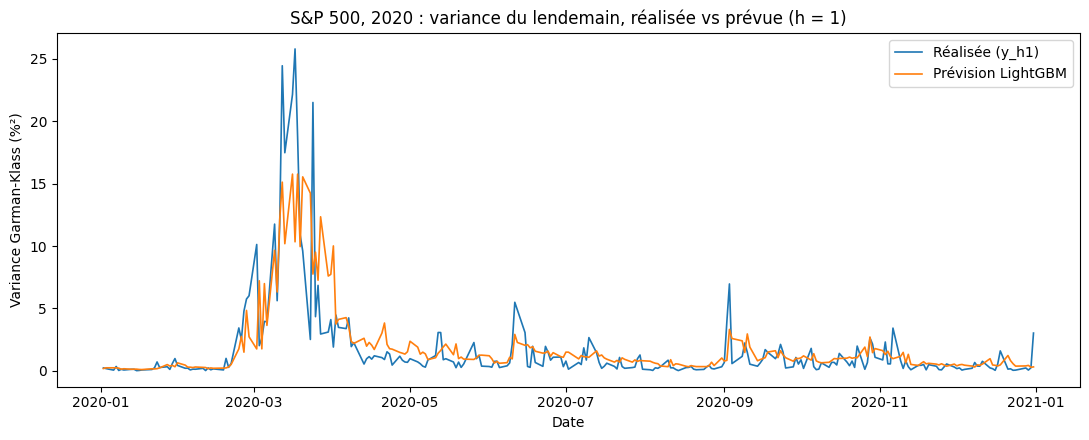

In [5]:
import matplotlib.pyplot as plt

d = resultats_gamma[1]
d = d[(d.date >= "2020-01-01") & (d.date <= "2020-12-31")]

plt.figure(figsize=(11, 4.5))
plt.plot(d.date, d.actual, label="Réalisée (y_h1)", lw=1.2)
plt.plot(d.date, d.forecast, label="Prévision LightGBM", lw=1.2)
plt.title("S&P 500, 2020 : variance du lendemain, réalisée vs prévue (h = 1)")
plt.xlabel("Date")
plt.ylabel("Variance Garman-Klass (%²)")
plt.legend()
plt.tight_layout()
(root / "figures").mkdir(exist_ok=True)
plt.savefig(root / "figures" / "fig5_lgbm_2020.png", dpi=200)
plt.show()

## LightGBM v1 : choix et observations

**Principe** : un modèle par horizon (1, 5 et 22 jours), réentraîné tous les 66 jours de bourse sur tout le passé disponible (fenêtre qui grandit), avec `iloc[:-h]` pour n'utiliser que des cibles déjà observées. Variables : rv_d, rv_w, rv_m, ret, ret_neg, vix. Paramètres fixés d'avance, aucun réglage sur le test.

**Problème rencontré** : avec la perte quadratique par défaut, le modèle a prédit une valeur négative les 26 et 27 décembre 2018. Le plancher à 0,0001 a donné une QLIKE de 25,16 à h = 1 (contre 0,396 pour le HAR), à cause de ces deux jours seulement. Un arbre peut prédire un nombre négatif, une variance non.

**Solution retenue** : `objective="gamma"`. Les prévisions sont toujours positives et la perte gamma vaut 2 fois la QLIKE : le modèle est entraîné sur la mesure qui sert à l'évaluer. Entraîner sur le logarithme sous-estimait la volatilité d'environ 24 % à h = 1.

**Limite** : le problème a été découvert en regardant le test, et plusieurs variantes ont été comparées sur ce même test. Gamma est donc présenté comme le choix justifié par le principe, pas comme la version qui gagne. Le réglage des paramètres se fera au sprint 4, uniquement sur 2000-2014.

**Contrôle visuel 2020** : la prévision suit le pic de mars avec un léger retard et ne l'anticipe pas : pas de fuite d'information.